# Sistema inteligente basado en redes neuronales convolucionales para la clasificación de células sanguíneas parasitadas por malaria como apoyo al análisis microscópico en establecimientos de salud con recursos limitados.

**Dataset:** NIH Malaria Cell Images  
**Fuente:** https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip

## 1. Importación de librerías

In [1]:
import hashlib
import io
import json
import os
import re
import stat
import time
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from IPython.display import Markdown, display
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, average_precision_score,
    confusion_matrix, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

ROOT = Path.cwd().resolve()
DATA, MODELS = ROOT / "data", ROOT / "models"
FIGURES, METRICS = ROOT / "results" / "figures", ROOT / "results" / "metrics"
for folder in (DATA, MODELS, FIGURES, METRICS):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
N_THREADS = min(6, os.cpu_count() or 1)
tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
CLASS_CODES = {"Uninfected": 0, "Parasitized": 1}
CLASS_NAMES = {0: "No parasitada", 1: "Parasitada"}

def show_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def read_rgb(relative_path):
    with Image.open(ROOT / relative_path) as image:
        return image.convert("RGB")

print(f"TensorFlow {tf.__version__} | scikit-learn {sklearn.__version__}")

TensorFlow 2.21.0 | scikit-learn 1.9.1


## 2. Carga del dataset

Se indexan las imágenes de la pareja de carpetas original. Las rutas del CSV son relativas a la carpeta del notebook.

Imágenes encontradas: 27,558


,imágenes
clase,
Parasitized,13779
Uninfected,13779


,ruta,clase,etiqueta
0,cell_images/Uninfected/C100P61ThinF_IMG_201509...,Uninfected,0
1,cell_images/Uninfected/C100P61ThinF_IMG_201509...,Uninfected,0
13779,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,1
13780,cell_images/Parasitized/C100P61ThinF_IMG_20150...,Parasitized,1


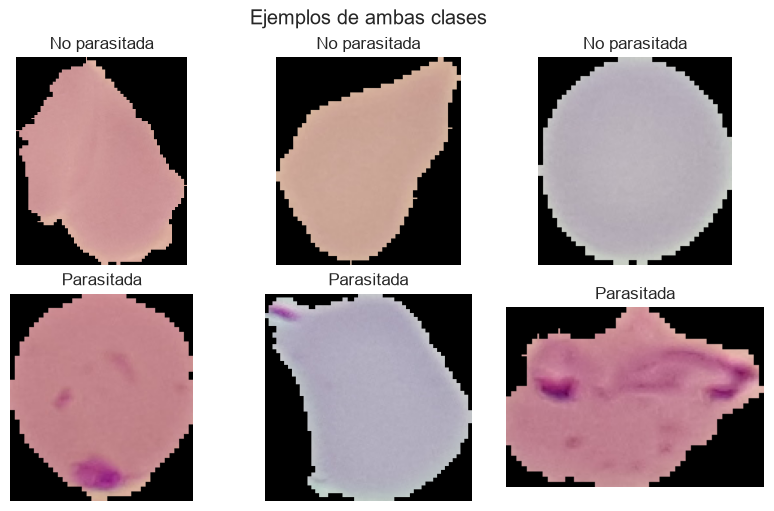

In [2]:
dataset_root = ROOT / "cell_images"
assert all((dataset_root / name).is_dir() for name in CLASS_CODES), (
    "Abre el notebook desde PROYECTO FINAL, junto a la carpeta cell_images."
)

records = []
for category, label in CLASS_CODES.items():
    paths = sorted((dataset_root / category).glob("*.png"))
    for path in paths:
        records.append({
            "ruta": path.relative_to(ROOT).as_posix(),
            "clase": category,
            "etiqueta": label,
        })

index = pd.DataFrame(records)
assert index.ruta.is_unique and set(index.etiqueta) == {0, 1}
index.to_csv(DATA / "dataset_malaria.csv", index=False)
print(f"Imágenes encontradas: {len(index):,}")
display(index.groupby("clase").size().rename("imágenes").to_frame())
display(index.groupby("clase", group_keys=False).head(2))

def gallery(frame, title, filename):
    fig, axes = plt.subplots(2, 3, figsize=(8, 5), layout="constrained")
    for ax, row in zip(axes.flat, frame.itertuples()):
        ax.imshow(read_rgb(row.ruta))
        ax.set_title(CLASS_NAMES[row.etiqueta])
        ax.axis("off")
    fig.suptitle(title)
    show_figure(fig, filename)

gallery(index.groupby("etiqueta").sample(n=3, random_state=SEED),
        "Ejemplos de ambas clases", "01_ejemplos")

## 3. Análisis exploratorio

Se revisan las dimensiones y el brillo de las imágenes originales. Para medir intensidad se toma la media de grises por imagen, incluyendo el fondo.

ancho                           alto                          \
              median    mean    std min  max median    mean    std min  max   
nombre_clase                                                                  
No parasitada  130.0  131.34  18.70  49  247  130.0  131.58  19.05  49  235   
Parasitada     133.0  133.63  21.19  46  394  133.0  134.39  21.99  40  385   

              intensidad                                
                  median    mean    std    min     max  
nombre_clase                                            
No parasitada     121.97  120.42  11.65  55.31  154.50  
Parasitada        115.20  113.57  12.28  53.06  150.43

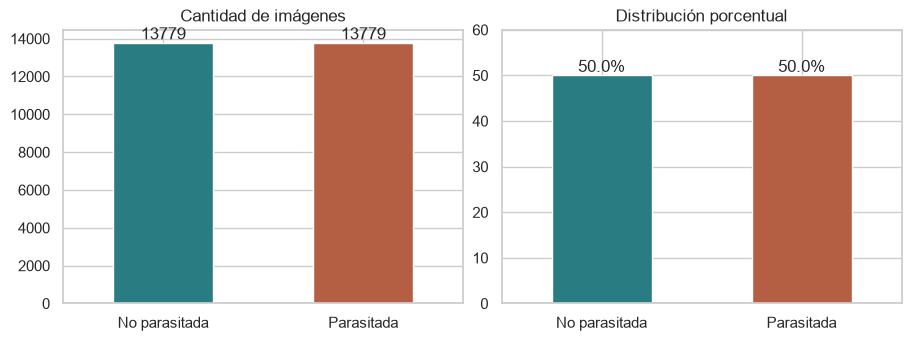

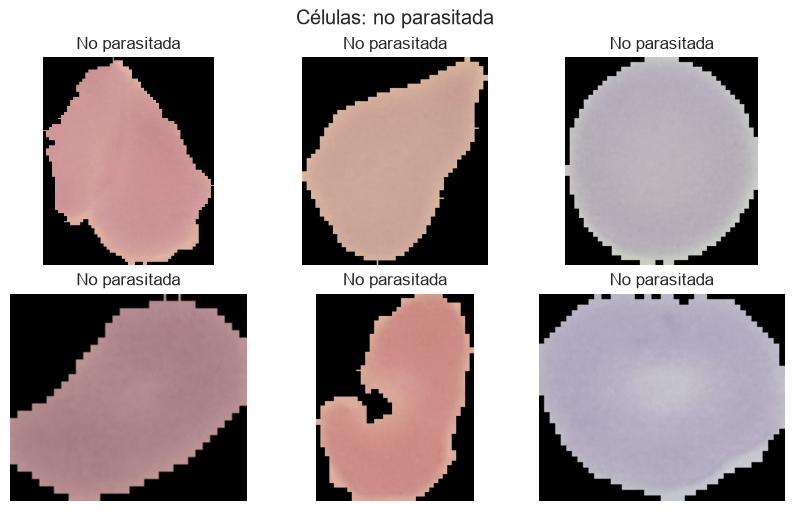

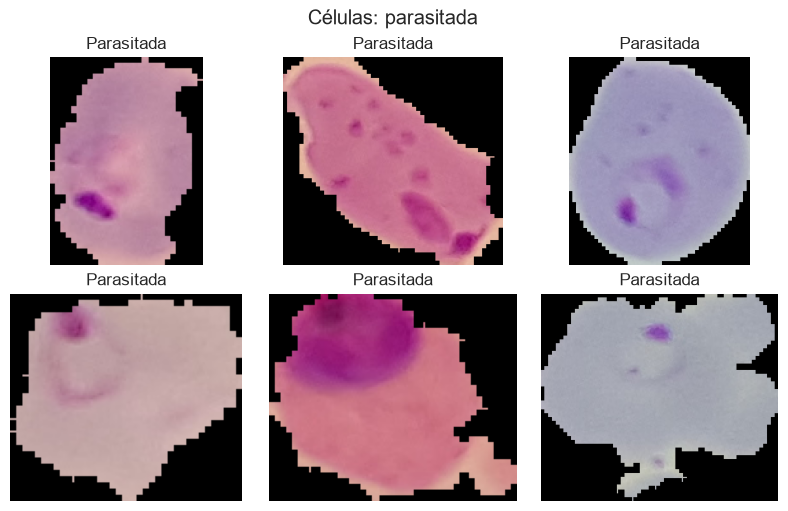

In [3]:
def inspect_image(relative_path):
    path = ROOT / relative_path
    attributes = getattr(path.stat(), "st_file_attributes", 0)
    recall_flags = (
        stat.FILE_ATTRIBUTE_OFFLINE | 0x00040000 | 0x00400000
        # Windows: RECALL_ON_OPEN y RECALL_ON_DATA_ACCESS.
    )
    if attributes & recall_flags:
        return {"error": "Archivo bajo demanda"}
    try:
        raw = path.read_bytes()
        with Image.open(io.BytesIO(raw)) as image:
            image.verify()
        with Image.open(io.BytesIO(raw)) as image:
            rgb = image.convert("RGB")
        w, h = rgb.size
        gray = np.asarray(rgb.convert("L"))
        content_hash = hashlib.sha256(f"{w}x{h}:".encode() + rgb.tobytes()).hexdigest()
        thumb = np.asarray(rgb.convert("L").resize((9, 8), Image.Resampling.BILINEAR))
        dhash = np.packbits(thumb[:, 1:] > thumb[:, :-1]).tobytes().hex()
        return {"ancho": w, "alto": h, "intensidad": gray.mean(),
                "sha256_archivo": hashlib.sha256(raw).hexdigest(),
                "sha256_rgb": content_hash, "dhash": dhash, "error": ""}
    except (OSError, ValueError, SyntaxError) as error:
        return {"error": str(error)}

with ThreadPoolExecutor(max_workers=N_THREADS) as workers:
    audit = index.join(pd.DataFrame(workers.map(inspect_image, index.ruta)))

readable = audit.loc[audit.error.eq("")].copy()
readable["nombre_clase"] = readable.etiqueta.map(CLASS_NAMES)
counts = readable.nombre_clase.value_counts().reindex(CLASS_NAMES.values())
eda = readable.groupby("nombre_clase")[["ancho", "alto", "intensidad"]].agg(
    ["median", "mean", "std", "min", "max"]
)
display(eda.round(2))
eda.to_csv(METRICS / "estadisticas_eda.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
counts.plot.bar(ax=axes[0], color=["#287c82", "#b45f43"], rot=0)
(counts / counts.sum() * 100).plot.bar(
    ax=axes[1], color=["#287c82", "#b45f43"], rot=0, ylim=(0, 60)
)
for ax, title in zip(axes, ("Cantidad de imágenes", "Distribución porcentual")):
    ax.set_title(title)
    ax.set_xlabel("")
    ax.bar_label(ax.containers[0], fmt="%.0f" if ax is axes[0] else "%.1f%%")
show_figure(fig, "02_distribucion_clases")

for label, name in CLASS_NAMES.items():
    gallery(readable.loc[readable.etiqueta.eq(label)].sample(n=6, random_state=SEED),
            f"Células: {name.lower()}", f"03_galeria_{label}")

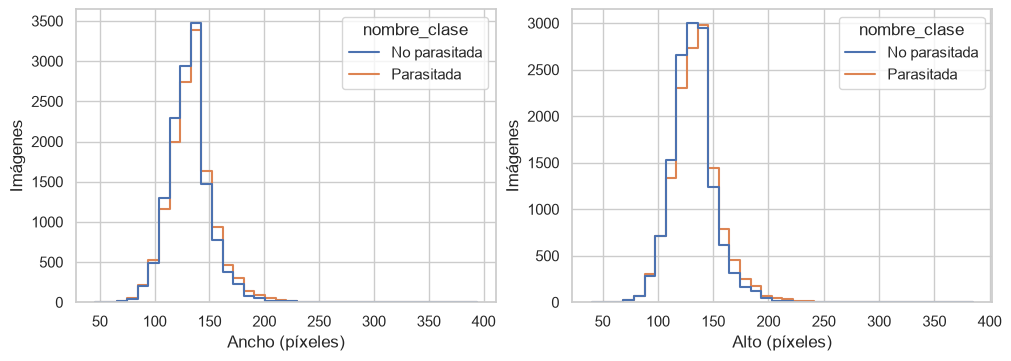

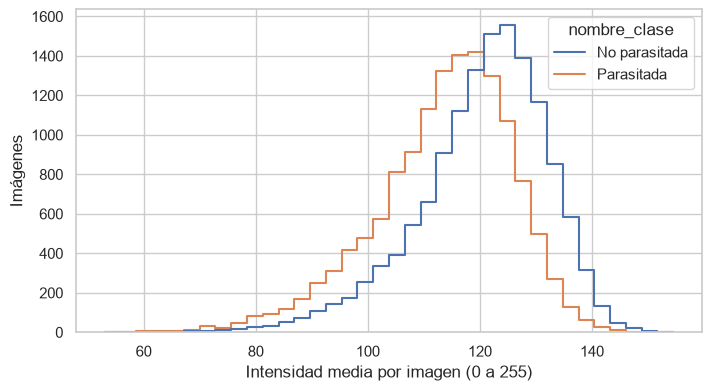

**Conclusión.** La clase parasitada representa 50.0% de las imágenes legibles. El ancho original va de 46 a 394 píxeles. La intensidad media fue 113.6 en parasitadas y 120.4 en no parasitadas.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, feature in zip(axes, ("ancho", "alto")):
    sns.histplot(readable, x=feature, hue="nombre_clase", bins=36,
                 element="step", fill=False, ax=ax)
    ax.set(xlabel=f"{feature.capitalize()} (píxeles)", ylabel="Imágenes")
show_figure(fig, "04_tamanos")

fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
sns.histplot(readable, x="intensidad", hue="nombre_clase", bins=36,
             element="step", fill=False, ax=ax)
ax.set(xlabel="Intensidad media por imagen (0 a 255)", ylabel="Imágenes")
show_figure(fig, "05_intensidades")

mean_gray = readable.groupby("etiqueta").intensidad.mean()
display(Markdown(
    f"**Conclusión.** La clase parasitada representa {counts.iloc[1] / counts.sum():.1%} "
    f"de las imágenes legibles. El ancho original va de {readable.ancho.min():.0f} a "
    f"{readable.ancho.max():.0f} píxeles. La intensidad media fue "
    f"{mean_gray[1]:.1f} en parasitadas y {mean_gray[0]:.1f} en no parasitadas."
))

## 4. Limpieza y preparación

Se verifica el archivo con Pillow y se compara el contenido RGB mediante SHA-256. La CNN usa imágenes de 48 × 48 con relleno para conservar la proporción. La capa Rescaling lleva los píxeles a [0, 1] y queda guardada en el modelo.

In [5]:
exact_files = int(readable.sha256_archivo.duplicated().sum())
exact_pixels = int(readable.sha256_rgb.duplicated().sum())
label_counts = readable.groupby("sha256_rgb").etiqueta.transform("nunique")
conflict = label_counts.gt(1)

audit["estado"] = "utilizada"
audit.loc[audit.error.ne(""), "estado"] = "inválida"
audit.loc[readable.index[conflict], "estado"] = "etiquetas en conflicto"
eligible = readable.loc[~conflict]
repeat = eligible.sha256_rgb.duplicated()
audit.loc[eligible.index[repeat], "estado"] = "duplicada"
clean = eligible.loc[~repeat].copy()
audit.to_csv(METRICS / "auditoria_imagenes.csv", index=False)

IMAGE_SIZE = (48, 48)

def resize_cell(image):
    return tf.image.resize_with_pad(image, *IMAGE_SIZE, antialias=True)

def decode_cell(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    return resize_cell(image), label

print(f"Legibles: {len(readable):,} | Inválidas o bajo demanda: {len(index) - len(readable):,}")
print(f"Copias exactas por archivo: {exact_files} | Por píxeles: {exact_pixels}")
display(audit.estado.value_counts().rename("imágenes").to_frame())

Legibles: 27,558 | Inválidas o bajo demanda: 0
Copias exactas por archivo: 0 | Por píxeles: 0


,imágenes
estado,
utilizada,27558


## 5. División del dataset

Los identificadores vienen de las tablas oficiales del NIH. Se forman siete bloques estratificados por etiqueta y agrupados por paciente. Se eligen validación y prueba según su cercanía al 15% por clase, con una semilla fija y sin usar predicciones.

In [6]:
patient_lookup = {}
for category in CLASS_CODES:
    mapping_file = DATA / f"patientid_cellmapping_{category.lower()}.csv"
    for line in mapping_file.read_text(encoding="utf-8-sig").splitlines():
        official_id, _, cell_list = line.partition(",")
        identifier = re.match(r"^C(\d+)[A-Z]*?P(\d+)", official_id, flags=re.I)
        if identifier:
            patient = f"P{int(identifier[2])}"
        else:
            patient = official_id.strip().upper()
        for filename in re.findall(r"'([^']+\.png)'", cell_list, re.I):
            key = (category, filename)
            assert patient_lookup.get(key, patient) == patient, key
            patient_lookup[key] = patient

mapped = [
    patient_lookup.get((row.clase, Path(row.ruta).name))
    for row in readable.itertuples()
]
readable["paciente"] = mapped
missing = readable.paciente.isna()
assert not missing.any(), f"{missing.sum()} imágenes sin paciente en las tablas del NIH."

# Si alguna imagen idéntica pertenecía a varios pacientes, se mantienen juntos.
parent = {patient: patient for patient in readable.paciente.unique()}

def group_root(patient):
    while patient != parent[patient]:
        patient = parent[patient]
    return patient

duplicates = readable.loc[readable.sha256_rgb.duplicated(keep=False)]
for _, images in duplicates.groupby("sha256_rgb"):
    anchor, *others = images.paciente.unique()
    for patient in others:
        parent[group_root(patient)] = group_root(anchor)

clean["paciente"] = readable.loc[clean.index, "paciente"]
clean["grupo"] = clean.paciente.map(group_root)
y = clean.etiqueta.to_numpy()
class_totals = np.bincount(y, minlength=2)
best_distance = float("inf")
for random_state in range(SEED, SEED + 12):
    splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=random_state)
    folds = [test for _, test in splitter.split(clean, y, groups=clean.grupo)]
    fold_counts = [np.bincount(y[fold], minlength=2) for fold in folds]
    for i, j in combinations(range(7), 2):
        fractions = np.stack([fold_counts[i], fold_counts[j]]) / class_totals
        distance = np.square(fractions - 0.15).sum()
        if distance < best_distance:
            best_distance = distance
            validation_rows, test_rows = folds[i], folds[j]
            split_seed = random_state

clean["conjunto"] = "entrenamiento"
clean.iloc[validation_rows, clean.columns.get_loc("conjunto")] = "validación"
clean.iloc[test_rows, clean.columns.get_loc("conjunto")] = "prueba"
partitions = {
    name: clean.loc[clean.conjunto.eq(name)].reset_index(drop=True)
    for name in ("entrenamiento", "validación", "prueba")
}
train, validation, test = partitions.values()
for a, b in combinations(partitions.values(), 2):
    for field in ("ruta", "paciente", "grupo", "sha256_archivo", "sha256_rgb"):
        assert set(a[field]).isdisjoint(b[field]), field
assert sum(map(len, partitions.values())) == len(clean)

cross_hashes = clean.groupby("dhash").conjunto.nunique().loc[lambda n: n > 1].index
candidates = clean.loc[clean.dhash.isin(cross_hashes), ["ruta", "dhash", "conjunto"]]
candidates.sort_values("dhash").to_csv(METRICS / "similitud_entre_conjuntos.csv", index=False)
clean[["ruta", "clase", "etiqueta", "paciente", "conjunto", "sha256_rgb"]].to_csv(
    DATA / "dataset_malaria.csv", index=False
)
summary = pd.crosstab(clean.conjunto, clean.nombre_clase).reindex(partitions)
summary["Total"] = summary.sum(axis=1)
summary["Proporción (%)"] = 100 * summary.Total / len(clean)
summary["Pacientes"] = clean.groupby("conjunto").paciente.nunique()
summary.to_csv(METRICS / "particiones.csv")
display(summary.round(2))
display(Markdown(
    f"**Conclusión.** Se usan {len(clean):,} imágenes de {clean.paciente.nunique()} pacientes. "
    f"No se repiten pacientes ni duplicados exactos entre conjuntos. El cribado "
    f"por huella dHash marcó {len(cross_hashes)} huellas coincidentes entre conjuntos "
    "como candidatas. Una coincidencia de dHash por sí sola no confirma un duplicado."
))

nombre_clase,No parasitada,Parasitada,Total,Proporción (%),Pacientes
conjunto,,,,,
entrenamiento,9801,9776,19577,71.04,142
validación,1983,1994,3977,14.43,29
prueba,1995,2009,4004,14.53,29


**Conclusión.** Se usan 27,558 imágenes de 200 pacientes. No se repiten pacientes ni duplicados exactos entre conjuntos. El cribado por huella dHash marcó 145 huellas coincidentes entre conjuntos como candidatas. Una coincidencia de dHash por sí sola no confirma un duplicado.

**Revisión de similitud.** Entre los 975 pares de distintos conjuntos con el mismo dHash, la menor diferencia media absoluta fue 8,51 sobre 255 al comparar miniaturas RGB de 48 × 48 con relleno. Ninguno quedó dentro del criterio de similitud estrecha de 3 niveles de intensidad.

## 6. Modelo baseline

La regresión logística usa histogramas de color, brillo, contraste y cambios vecinos de intensidad. Se ajusta el escalado con el conjunto de entrenamiento.

In [7]:
def visual_features(relative_path):
    image = read_rgb(relative_path)
    rgb = np.asarray(image, dtype=np.float32) / 255.0
    cell = rgb[np.any(rgb > 0, axis=-1)]
    if not len(cell):
        cell = np.zeros((1, 3), dtype=np.float32)
    histograms = [np.histogram(channel, bins=12, range=(0, 1))[0] / len(cell)
                  for channel in cell.T]
    gray = np.asarray(image.convert("L"), dtype=np.float32) / 255.0
    edges = [np.abs(np.diff(gray, axis=axis)).mean() if gray.shape[axis] > 1 else 0.0
             for axis in (0, 1)]
    return np.concatenate([
        cell.mean(axis=0), cell.std(axis=0), *histograms,
        [gray.mean(), gray.std(), *edges, len(cell) / gray.size],
    ])

def feature_matrix(frame):
    with ThreadPoolExecutor(max_workers=N_THREADS) as workers:
        return np.stack(list(workers.map(visual_features, frame.ruta)))

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=SEED))
x_train = feature_matrix(train)
baseline.fit(x_train, train.etiqueta)
print(f"Regresión logística ajustada con {x_train.shape[1]} características por imagen.")

Regresión logística ajustada con 47 características por imagen.


## 7. Construcción de la CNN 2D

Se comparan dos redes con tres bloques convolucionales. La versión B tiene más filtros. El resumen muestra el tamaño de cada capa y el número de parámetros.

In [8]:
CONFIGS = {"CNN A": (8, 16, 24), "CNN B": (12, 24, 40)}

def build_cnn(name, filters):
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="imagen")
    x = layers.Rescaling(1 / 255)(inputs)
    x = layers.RandomFlip("horizontal_and_vertical", seed=SEED)(x)
    for block, channels in enumerate(filters, start=1):
        stride = 2 if block == 1 else 1
        x = layers.Conv2D(channels, 3, strides=stride, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU(name=f"relu_conv_{block}")(x)
        if block < len(filters):
            x = layers.MaxPooling2D()(x)
    average = layers.GlobalAveragePooling2D()(x)
    maximum = layers.GlobalMaxPooling2D()(x)
    x = layers.Concatenate()([average, maximum])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.20, seed=SEED)(x)
    logits = layers.Dense(1, name="logit")(x)
    probability = layers.Activation("sigmoid", name="probabilidad")(logits)
    return keras.Model(inputs, probability, name=name.lower().replace(" ", "_"))

for name, filters in CONFIGS.items():
    build_cnn(name, filters).summary(line_length=82)

Model: "cnn_a"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape       ┃     Param # ┃ Connected to        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)   │ (None, 48, 48, 3)  │           0 │ -                   │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ rescaling (Rescaling) │ (None, 48, 48, 3)  │           0 │ imagen[0][0]        │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ random_flip           │ (None, 48, 48, 3)  │           0 │ rescaling[0][0]     │
│ (RandomFlip)          │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ conv2d (Conv2D)       │ (None, 24, 24, 8)  │         216 │ random_flip[0][0]   │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ batch_normalization   │ (None, 24, 24, 8)  │          32 │ conv2d[0][0]        │
│ (BatchNormalization)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ relu_conv_1 (ReLU)    │ (None, 24, 24, 8)  │           0 │ batch_normalizatio… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ max_pooling2d         │ (None, 12, 12, 8)  │           0 │ relu_conv_1[0][0]   │
│ (MaxPooling2D)        │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ conv2d_1 (Conv2D)     │ (None, 12, 12, 16) │       1,152 │ max_pooling2d[0][0] │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ batch_normalization_1 │ (None, 12, 12, 16) │          64 │ conv2d_1[0][0]      │
│ (BatchNormalization)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ relu_conv_2 (ReLU)    │ (None, 12, 12, 16) │           0 │ batch_normalizatio… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ max_pooling2d_1       │ (None, 6, 6, 16)   │           0 │ relu_conv_2[0][0]   │
│ (MaxPooling2D)        │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ conv2d_2 (Conv2D)     │ (None, 6, 6, 24)   │       3,456 │ max_pooling2d_1[0]… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ batch_normalization_2 │ (None, 6, 6, 24)   │          96 │ conv2d_2[0][0]      │
│ (BatchNormalization)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ relu_conv_3 (ReLU)    │ (None, 6, 6, 24)   │           0 │ batch_normalizatio… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ global_average_pooli… │ (None, 24)         │           0 │ relu_conv_3[0][0]   │
│ (GlobalAveragePoolin… │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ global_max_pooling2d  │ (None, 24)         │           0 │ relu_conv_3[0][0]   │
│ (GlobalMaxPooling2D)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ concatenate           │ (None, 48)         │           0 │ global_average_poo… │
│ (Concatenate)         │                    │             │ global_max_pooling… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ dense (Dense)         │ (None, 32)         │       1,568 │ concatenate[0][0]   │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ dropout (Dropo

 Total params: 6,617 (25.85 KB)

 Trainable params: 6,521 (25.47 KB)

 Non-trainable params: 96 (384.00 B)

Model: "cnn_b"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape       ┃     Param # ┃ Connected to        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)   │ (None, 48, 48, 3)  │           0 │ -                   │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ rescaling_1           │ (None, 48, 48, 3)  │           0 │ imagen[0][0]        │
│ (Rescaling)           │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ random_flip_1         │ (None, 48, 48, 3)  │           0 │ rescaling_1[0][0]   │
│ (RandomFlip)          │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ conv2d_3 (Conv2D)     │ (None, 24, 24, 12) │         324 │ random_flip_1[0][0] │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ batch_normalization_3 │ (None, 24, 24, 12) │          48 │ conv2d_3[0][0]      │
│ (BatchNormalization)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ relu_conv_1 (ReLU)    │ (None, 24, 24, 12) │           0 │ batch_normalizatio… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ max_pooling2d_2       │ (None, 12, 12, 12) │           0 │ relu_conv_1[0][0]   │
│ (MaxPooling2D)        │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ conv2d_4 (Conv2D)     │ (None, 12, 12, 24) │       2,592 │ max_pooling2d_2[0]… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ batch_normalization_4 │ (None, 12, 12, 24) │          96 │ conv2d_4[0][0]      │
│ (BatchNormalization)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ relu_conv_2 (ReLU)    │ (None, 12, 12, 24) │           0 │ batch_normalizatio… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ max_pooling2d_3       │ (None, 6, 6, 24)   │           0 │ relu_conv_2[0][0]   │
│ (MaxPooling2D)        │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ conv2d_5 (Conv2D)     │ (None, 6, 6, 40)   │       8,640 │ max_pooling2d_3[0]… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ batch_normalization_5 │ (None, 6, 6, 40)   │         160 │ conv2d_5[0][0]      │
│ (BatchNormalization)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ relu_conv_3 (ReLU)    │ (None, 6, 6, 40)   │           0 │ batch_normalizatio… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ global_average_pooli… │ (None, 40)         │           0 │ relu_conv_3[0][0]   │
│ (GlobalAveragePoolin… │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ global_max_pooling2d… │ (None, 40)         │           0 │ relu_conv_3[0][0]   │
│ (GlobalMaxPooling2D)  │                    │             │                     │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ concatenate_1         │ (None, 80)         │           0 │ global_average_poo… │
│ (Concatenate)         │                    │             │ global_max_pooling… │
├───────────────────────┼────────────────────┼─────────────┼─────────────────────┤
│ dense_1 (Dense)       │ (None, 32)         │       2,592 │ concatenate_1[0][0] │
├───────────────

 Total params: 14,485 (56.58 KB)

 Trainable params: 14,333 (55.99 KB)

 Non-trainable params: 152 (608.00 B)

## 8. Entrenamiento

Se leen los PNG por lotes con tf.data. Adam optimiza la entropía cruzada binaria. EarlyStopping y ModelCheckpoint usan la pérdida de validación para conservar la mejor época.

In [9]:
from tempfile import TemporaryDirectory

gpu_devices = tf.config.list_physical_devices("GPU")
BATCH_SIZE = 96
EPOCHS = 12
PATIENCE = 3
LEARNING_RATE = 0.0015
print(f"Dispositivo: {gpu_devices if gpu_devices else 'CPU'} | Lote: {BATCH_SIZE}")

def make_dataset(frame, shuffle=False):
    paths = [str(ROOT / path) for path in frame.ruta]
    labels = frame.etiqueta.to_numpy(dtype=np.float32).reshape(-1, 1)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = N_THREADS
    options.threading.max_intra_op_parallelism = 1
    return (dataset.with_options(options)
            .map(decode_cell, num_parallel_calls=N_THREADS)
            .batch(BATCH_SIZE).prefetch(2))

histories = {}
trained = {}
start_training = time.perf_counter()
with TemporaryDirectory(prefix="malaria-cnn-") as checkpoints:
    for name, filters in CONFIGS.items():
        keras.utils.set_random_seed(SEED)
        train_ds = make_dataset(train, shuffle=True)
        validation_ds = make_dataset(validation)
        model = build_cnn(name, filters)
        model.compile(
            optimizer=keras.optimizers.Adam(LEARNING_RATE),
            loss=keras.losses.BinaryCrossentropy(),
            metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
        )
        model_path = Path(checkpoints) / f"{model.name}.keras"
        history_path = METRICS / f"historial_{model.name}.csv"
        print(f"Entrenando {name}...", flush=True)
        model.fit(
            train_ds, validation_data=validation_ds, epochs=EPOCHS, verbose=0,
            callbacks=[
                keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                               restore_best_weights=True),
                keras.callbacks.ModelCheckpoint(model_path, monitor="val_loss",
                                                save_best_only=True),
                keras.callbacks.CSVLogger(history_path),
            ],
        )
        histories[name] = pd.read_csv(history_path).assign(
            epoch=lambda df: df.epoch + 1
        ).set_index("epoch")
        histories[name].to_csv(history_path)
        trained[name] = keras.models.load_model(model_path)
        print(f"{name}: {len(histories[name])} épocas, {model.count_params():,} parámetros.",
              flush=True)

training_seconds = time.perf_counter() - start_training
print(f"Tiempo de las dos CNN: {training_seconds / 60:.1f} min")

Dispositivo: CPU | Lote: 96


Entrenando CNN A...


CNN A: 8 épocas, 6,617 parámetros.


Entrenando CNN B...


CNN B: 9 épocas, 14,485 parámetros.


Tiempo de las dos CNN: 1.8 min


## 9. Gráficos de entrenamiento

**CNN A.** La pérdida de validación fue 1.142 en la primera época y 0.112 en su mínimo (época 5). En esa época, accuracy fue 96.1% en entrenamiento y 96.1% en validación.

**CNN B.** La pérdida de validación fue 1.094 en la primera época y 0.108 en su mínimo (época 6). En esa época, accuracy fue 96.4% en entrenamiento y 96.2% en validación.

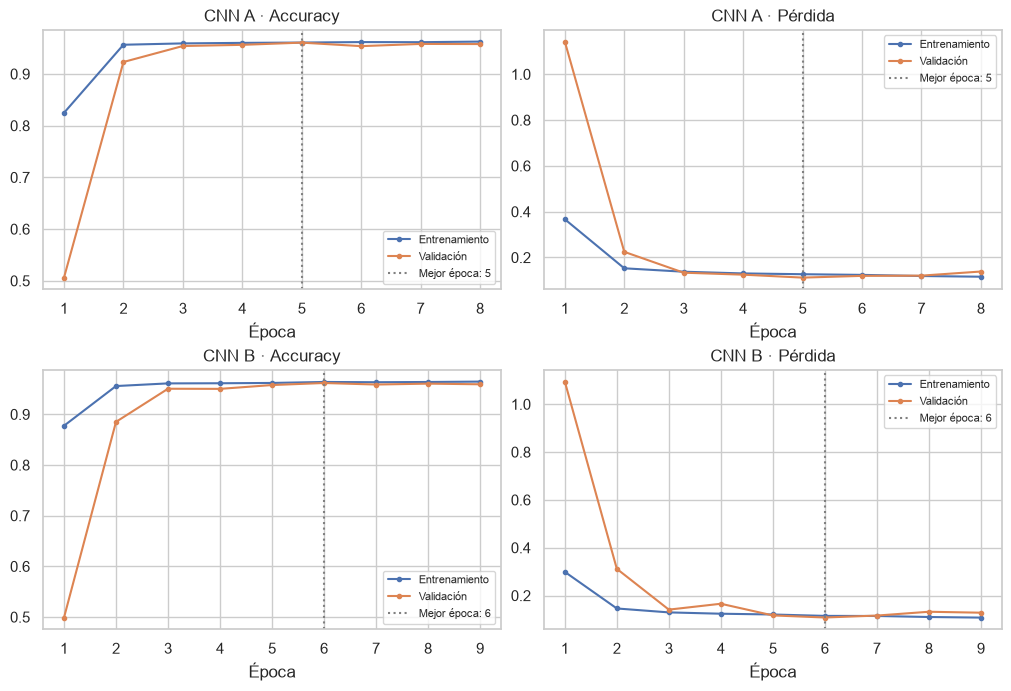

In [10]:
fig, axes = plt.subplots(len(histories), 2, figsize=(10, 6.8), layout="constrained")
experiment_rows = []
for row, (name, h) in enumerate(histories.items()):
    best_epoch = int(h.val_loss.idxmin())
    for column, (metric, title) in enumerate((("accuracy", "Accuracy"), ("loss", "Pérdida"))):
        ax = axes[row, column]
        ax.plot(h.index, h[metric], marker=".", label="Entrenamiento")
        ax.plot(h.index, h[f"val_{metric}"], marker=".", label="Validación")
        ax.axvline(best_epoch, color="gray", linestyle=":", label=f"Mejor época: {best_epoch}")
        ax.set(xlabel="Época", title=f"{name} · {title}", xticks=h.index)
        ax.legend(fontsize=8)
    experiment_rows.append({
        "modelo": name, "filtros": "/".join(map(str, CONFIGS[name])),
        "parametros": trained[name].count_params(), "epocas": len(h),
        "mejor_epoca": best_epoch, "val_loss": h.loc[best_epoch, "val_loss"],
        "val_accuracy": h.loc[best_epoch, "val_accuracy"],
    })
    first, best = h.iloc[0], h.loc[best_epoch]
    display(Markdown(
        f"**{name}.** La pérdida de validación fue {first.val_loss:.3f} en la primera "
        f"época y {best.val_loss:.3f} en su mínimo (época {best_epoch}). "
        f"En esa época, accuracy fue {best.accuracy:.1%} en entrenamiento "
        f"y {best.val_accuracy:.1%} en validación."
    ))
show_figure(fig, "06_entrenamiento")
experiments = pd.DataFrame(experiment_rows).set_index("modelo").sort_values("val_loss")

## 10. Evaluación

Se fija el umbral en 0.50 y se toma la clase parasitada como positiva. PR-AUC se calcula como el área trapezoidal de la curva precisión-recall. Se reporta también AP (precisión promedio), que integra la curva de otra manera.

In [11]:
THRESHOLD = 0.5

def score_model(labels, probabilities):
    predicted = (probabilities >= THRESHOLD).astype(int)
    precision_curve, recall_curve, _ = precision_recall_curve(labels, probabilities)
    return {
        "Accuracy": accuracy_score(labels, predicted),
        "Precision": precision_score(labels, predicted, zero_division=0),
        "Recall": recall_score(labels, predicted, zero_division=0),
        "F1": f1_score(labels, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(labels, probabilities),
        "PR-AUC": auc(recall_curve, precision_curve),
        "AP": average_precision_score(labels, probabilities),
    }

validation_prob = {"Baseline": baseline.predict_proba(feature_matrix(validation))[:, 1]}
validation_prob.update({
    name: model.predict(validation_ds, verbose=0).ravel()
    for name, model in trained.items()
})
validation_scores = pd.DataFrame({
    name: score_model(validation.etiqueta, p) for name, p in validation_prob.items()
}).T
validation_scores.to_csv(METRICS / "metricas_validacion.csv", index_label="modelo")
display(validation_scores.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,AP
Baseline,0.9060,0.9259,0.8831,0.9040,0.9512,0.9421,0.9420
CNN A,0.9605,0.9674,0.9534,0.9603,0.9914,0.9917,0.9917
CNN B,0.9618,0.9747,0.9483,0.9614,0.9928,0.9935,0.9935


## 11. Experimentos y prueba reservada

Se elige la CNN con menor pérdida en validación. Luego se comparan la CNN elegida y la regresión logística sobre las mismas imágenes de prueba. Los resultados de prueba se usan para informar el desempeño.

,filtros,parametros,epocas,mejor_epoca,val_loss,val_accuracy
modelo,,,,,,
CNN B,12/24/40,14485,9,6,0.1082,0.9618
CNN A,8/16/24,6617,8,5,0.1122,0.9605


CNN seleccionada: CNN B | Modelo guardado: models\modelo_malaria_cnn.keras


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,AP
Baseline,0.8911,0.9544,0.8223,0.8834,0.9127,0.9392,0.9392
CNN B,0.9438,0.9750,0.9114,0.9421,0.9869,0.9865,0.9865


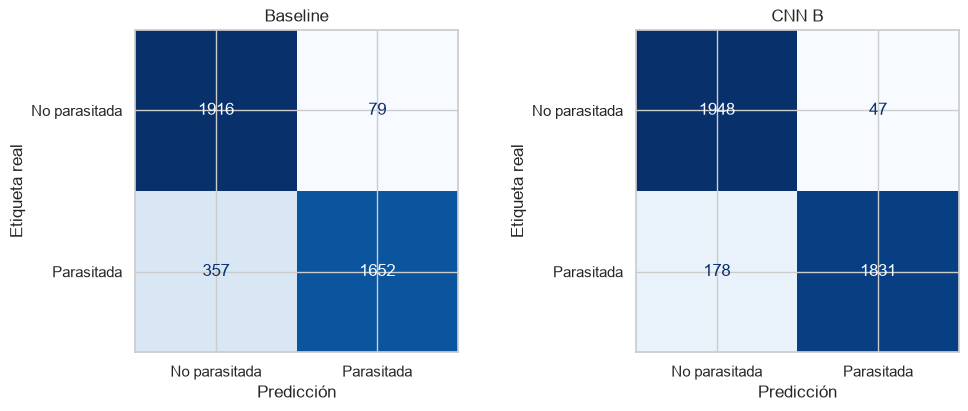

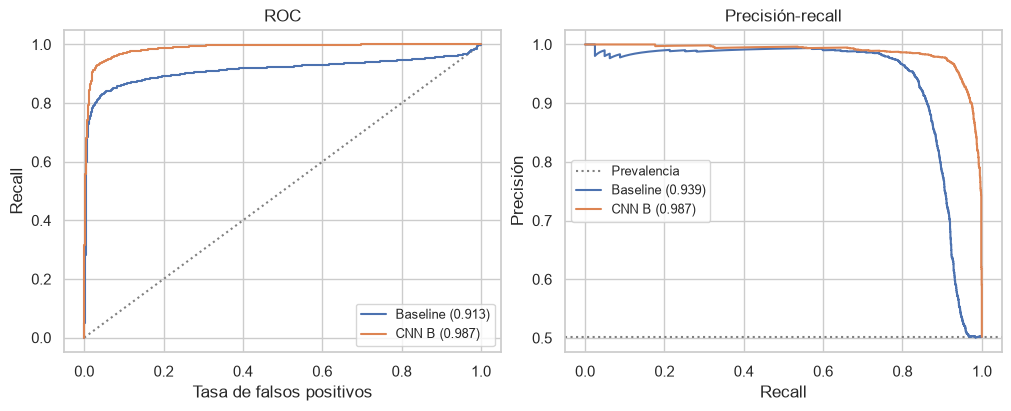

In [12]:
experiments.to_csv(METRICS / "experimentos_cnn.csv")
display(experiments.round(4))

winner = experiments.index[0]
best_model = trained[winner]
final_path = MODELS / "modelo_malaria_cnn.keras"
best_model.save(final_path)
best_model = keras.models.load_model(final_path)
config = {
    "modelo": winner, "filtros": CONFIGS[winner], "parametros": best_model.count_params(),
    "tamano_rgb": [*IMAGE_SIZE, 3], "lote": BATCH_SIZE, "max_epocas": EPOCHS,
    "mejor_epoca": int(experiments.loc[winner, "mejor_epoca"]),
    "paciencia": PATIENCE, "optimizador": "Adam", "learning_rate": LEARNING_RATE,
    "criterio_seleccion": "val_loss", "umbral": THRESHOLD, "etiquetas": CLASS_CODES,
    "semilla": SEED, "semilla_division": split_seed, "tensorflow": tf.__version__,
    "dispositivo": "GPU" if gpu_devices else "CPU", "segundos_entrenamiento": training_seconds,
}
(METRICS / "configuracion.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
(METRICS / "arquitectura_cnn.json").write_text(best_model.to_json(), encoding="utf-8")

y_test = test.etiqueta.to_numpy()
probabilities = {
    "Baseline": baseline.predict_proba(feature_matrix(test))[:, 1],
    winner: best_model.predict(make_dataset(test), verbose=0).ravel(),
}
comparison = pd.DataFrame({
    name: score_model(y_test, p) for name, p in probabilities.items()
}).T
comparison.to_csv(METRICS / "metricas_prueba.csv", index_label="modelo")
print(f"CNN seleccionada: {winner} | Modelo guardado: {final_path.relative_to(ROOT)}")
display(comparison.round(4))

results = test[["ruta", "paciente", "etiqueta"]].copy()
results["prob_baseline"] = probabilities["Baseline"]
results["prob_cnn"] = probabilities[winner]
results["pred_baseline"] = (results.prob_baseline >= THRESHOLD).astype(int)
results["pred_cnn"] = (results.prob_cnn >= THRESHOLD).astype(int)
results.to_csv(METRICS / "predicciones_prueba.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, p) in zip(axes, probabilities.items()):
    matrix = confusion_matrix(y_test, p >= THRESHOLD, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=list(CLASS_NAMES.values())).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set(title=name, xlabel="Predicción", ylabel="Etiqueta real")
show_figure(fig, "07_matrices_confusion")

fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="gray")
pr_ax.axhline(y_test.mean(), linestyle=":", color="gray", label="Prevalencia")
for name, p in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    precision, recall, _ = precision_recall_curve(y_test, p)
    roc_ax.plot(fpr, tpr, label=f"{name} ({comparison.loc[name, 'ROC-AUC']:.3f})")
    pr_ax.plot(recall, precision, label=f"{name} ({comparison.loc[name, 'PR-AUC']:.3f})")
roc_ax.set(title="ROC", xlabel="Tasa de falsos positivos", ylabel="Recall")
pr_ax.set(title="Precisión-recall", xlabel="Recall", ylabel="Precisión")
for ax in (roc_ax, pr_ax):
    ax.legend(fontsize=9)
show_figure(fig, "08_curvas_roc_pr")

## 12. Mapas de calor Grad-CAM

Grad-CAM muestra las zonas que más apoyaron la clase predicha en la última capa convolucional. Los colores cálidos indican mayor aporte en esa imagen.

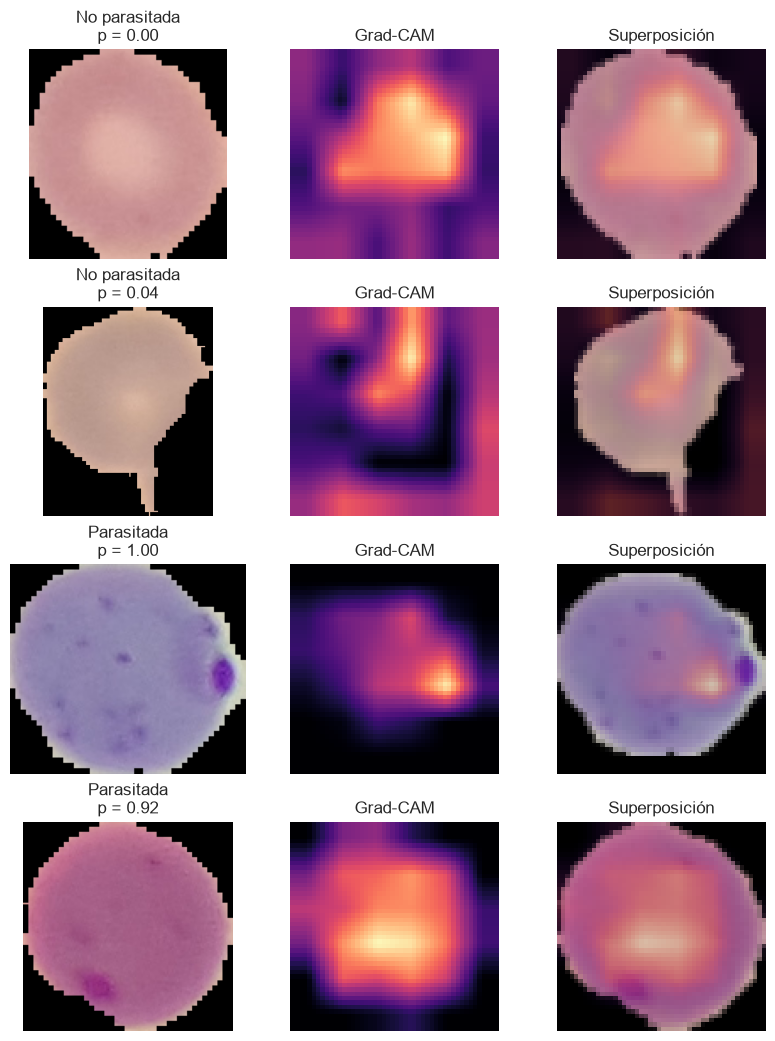

**Lectura de los mapas.** Las coordenadas de máxima activación en la entrada de 48 × 48 fueron fila 1: (35, 20), fila 2: (27, 11), fila 3: (35, 27), fila 4: (20, 27). La superposición permite observar si estas zonas caen en el interior de la célula, el borde o el fondo. El mapa describe la respuesta del modelo.

In [13]:
activation_model = keras.Model(
    best_model.input,
    [best_model.get_layer("relu_conv_3").output, best_model.get_layer("logit").output],
)

def grad_cam(relative_path, predicted_label):
    original = read_rgb(relative_path)
    image = resize_cell(tf.convert_to_tensor(np.asarray(original)))[None, ...]
    with tf.GradientTape() as tape:
        features, logits = activation_model(image, training=False)
        score = logits[0, 0] if predicted_label == 1 else -logits[0, 0]
    gradients = tape.gradient(score, features)[0]
    weights = tf.reduce_mean(gradients, axis=(0, 1))
    heat = tf.nn.relu(tf.reduce_sum(features[0] * weights, axis=-1))
    heat = tf.math.divide_no_nan(heat, tf.reduce_max(heat))
    heat = tf.image.resize(heat[..., None], IMAGE_SIZE)[..., 0].numpy()
    return original, np.clip(image[0].numpy() / 255, 0, 1), heat

correct = results.loc[results.etiqueta.eq(results.pred_cnn)]
grad_examples = correct.groupby("etiqueta", group_keys=False).sample(n=2, random_state=SEED)
fig, axes = plt.subplots(4, 3, figsize=(8, 10.3), layout="constrained")
positions = []
for row, example in enumerate(grad_examples.itertuples()):
    original, model_image, heat = grad_cam(example.ruta, example.pred_cnn)
    axes[row, 0].imshow(original)
    axes[row, 1].imshow(heat, cmap="magma", vmin=0, vmax=1)
    axes[row, 2].imshow(model_image)
    axes[row, 2].imshow(heat, alpha=0.62 * heat, cmap="magma", vmin=0, vmax=1)
    axes[row, 0].set_title(f"{CLASS_NAMES[example.pred_cnn]}\np = {example.prob_cnn:.2f}")
    axes[row, 1].set_title("Grad-CAM")
    axes[row, 2].set_title("Superposición")
    for ax in axes[row]:
        ax.axis("off")
    if heat.max() > 0:
        peak_y, peak_x = np.unravel_index(heat.argmax(), heat.shape)
        positions.append(f"fila {row + 1}: ({peak_x}, {peak_y})")
show_figure(fig, "09_grad_cam")
display(Markdown(
    "**Lectura de los mapas.** Las coordenadas de máxima activación en la entrada "
    f"de 48 × 48 fueron {', '.join(positions) or 'ninguna (mapas nulos)'}. "
    "La superposición permite observar si estas zonas caen en el interior de la célula, "
    "el borde o el fondo. El mapa describe la respuesta del modelo."
))

**Observación.** En la tercera fila, la activación más alta cae a la derecha del centro, cerca de la mancha morada del borde. En la cuarta fila se concentra en una zona interior más amplia. El segundo ejemplo también muestra activación en el fondo inferior.

## 13. Análisis de errores

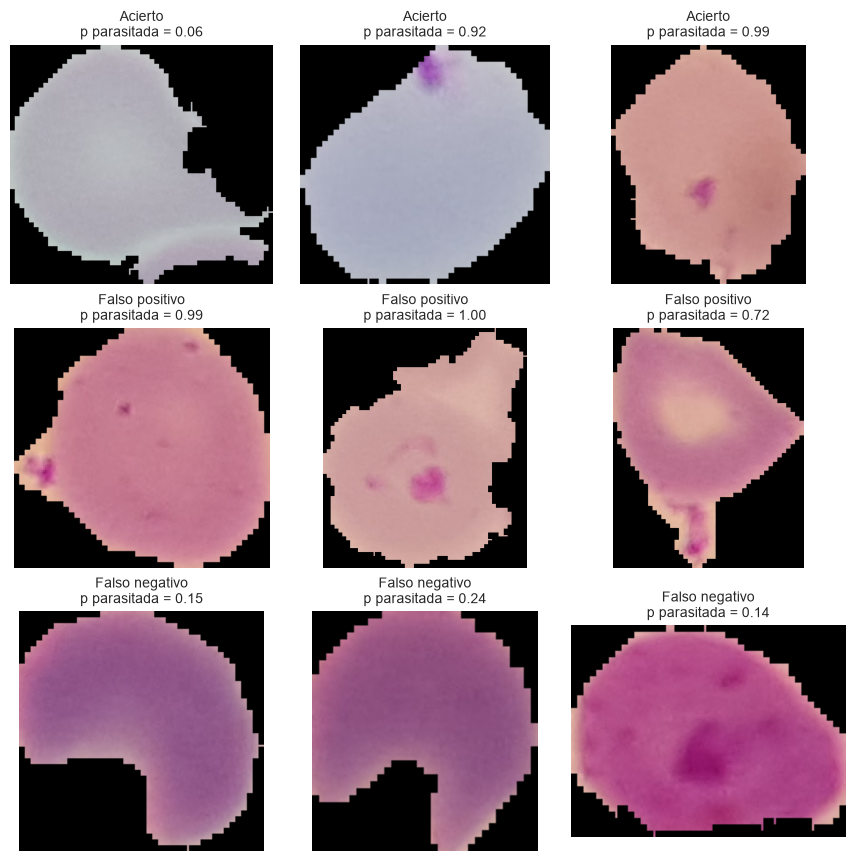

**Lectura de los errores.** La CNN marcó 47 células no parasitadas como positivas y dejó pasar 178 células parasitadas. De esos errores, 6 falsos positivos y 26 falsos negativos quedaron a una distancia de hasta 0.10 del umbral.

In [14]:
false_positive = results.loc[results.etiqueta.eq(0) & results.pred_cnn.eq(1)]
false_negative = results.loc[results.etiqueta.eq(1) & results.pred_cnn.eq(0)]

fig, axes = plt.subplots(3, 3, figsize=(8.5, 8.5), layout="constrained")
for row, (title, frame) in enumerate([
    ("Acierto", correct), ("Falso positivo", false_positive), ("Falso negativo", false_negative)
]):
    examples = list(frame.sample(n=min(3, len(frame)), random_state=SEED).itertuples())
    for column, ax in enumerate(axes[row]):
        ax.axis("off")
        if column < len(examples):
            example = examples[column]
            ax.imshow(read_rgb(example.ruta))
            ax.set_title(f"{title}\np parasitada = {example.prob_cnn:.2f}", fontsize=10)
        else:
            ax.set_title(f"{title}\nSin ejemplo adicional", fontsize=10)
show_figure(fig, "10_analisis_errores")

near_fp = false_positive.prob_cnn.between(0.5, 0.6).sum()
near_fn = false_negative.prob_cnn.between(0.4, 0.5).sum()
display(Markdown(
    f"**Lectura de los errores.** La CNN marcó {len(false_positive)} células no parasitadas "
    f"como positivas y dejó pasar {len(false_negative)} células parasitadas. "
    f"De esos errores, {near_fp} falsos positivos y {near_fn} falsos negativos "
    "quedaron a una distancia de hasta 0.10 del umbral."
))

**Observación.** Los tres falsos positivos de la galería muestran manchas moradas en el interior o cerca del borde. Dos falsos negativos tienen un contorno curvado con una parte recortada. Son rasgos visibles en los ejemplos.

## 14. Conclusiones técnicas

In [15]:
cnn = comparison.loc[winner]
reference = comparison.loc["Baseline"]
notes = [
    f"Se verificaron {len(readable):,} imágenes legibles. Se usaron {len(clean):,} "
    f"después de revisar duplicados y se comprobaron {clean.paciente.nunique()} pacientes "
    "sin solapamiento entre los tres conjuntos.",
    f"De las dos arquitecturas, {winner} obtuvo la menor pérdida de validación "
    f"({experiments.loc[winner, 'val_loss']:.3f}) en la época "
    f"{int(experiments.loc[winner, 'mejor_epoca'])}.",
    f"En las {len(test):,} imágenes de prueba, la CNN obtuvo accuracy de {cnn.Accuracy:.1%}, "
    f"F1 de {cnn.F1:.3f} y ROC-AUC de {cnn['ROC-AUC']:.3f}. "
    f"El baseline obtuvo F1 de {reference.F1:.3f} y ROC-AUC de {reference['ROC-AUC']:.3f}.",
    f"Con el umbral de {THRESHOLD:.2f}, la CNN tuvo {len(false_positive)} falsos positivos "
    f"y {len(false_negative)} falsos negativos.",
]
display(Markdown("\n".join(f"- {note}" for note in notes)))

- Se verificaron 27,558 imágenes legibles. Se usaron 27,558 después de revisar duplicados y se comprobaron 200 pacientes sin solapamiento entre los tres conjuntos.
- De las dos arquitecturas, CNN B obtuvo la menor pérdida de validación (0.108) en la época 6.
- En las 4,004 imágenes de prueba, la CNN obtuvo accuracy de 94.4%, F1 de 0.942 y ROC-AUC de 0.987. El baseline obtuvo F1 de 0.883 y ROC-AUC de 0.913.
- Con el umbral de 0.50, la CNN tuvo 47 falsos positivos y 178 falsos negativos.